# Reinforcement learning on arithmetic

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shoaibphysics/arithmetic-post-training/blob/main/notebooks/02_grpo.ipynb)

Can correctness rewards improve the arithmetic performance of our
supervised fine-tuned model?

We start from the SFT checkpoint saved in notebook 01. Before training,
we compare harder tasks to identify one that provides useful reward
variation for Group Relative Policy Optimization (GRPO).

### Setup

Locally, use the project's Python environment and saved SFT adapter.

In Colab, select a GPU runtime. The SFT adapter must be available under
`MyDrive/arithmetic-post-training/runs/sft/adapter`, either copied from
the local run or produced by running notebook 01 there.

In [1]:
import sys

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    %pip install -q transformers==5.18.0 trl==1.16.0 peft==0.21.2 datasets==5.1.0 accelerate==1.15.0 pandas==3.0.6 matplotlib==3.11.2
    %pip install -q --no-deps git+https://github.com/shoaibphysics/arithmetic-post-training.git@main

In [2]:
from pathlib import Path

import pandas as pd
import torch
from peft import PeftModel
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed

from arithmetic_post_training.arithmetic import make_harder_data
from arithmetic_post_training.evaluation import evaluate_arithmetic

set_seed(42)
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    project_root = Path("/content/drive/MyDrive/arithmetic-post-training")
else:
    project_root = Path.cwd()
    if project_root.name == "notebooks":
        project_root = project_root.parent

adapter_dir = project_root / "runs" / "sft" / "adapter"
run_dir = project_root / "runs" / "grpo"
asset_dir = project_root / "assets" / "grpo"
run_dir.mkdir(parents=True, exist_ok=True)
asset_dir.mkdir(parents=True, exist_ok=True)

print("Device:", device)
print("Starting adapter:", adapter_dir)
print("Run outputs:", run_dir)
print("README assets:", asset_dir)

/Users/shoaibakhtar/Developer/reasoning-models/arithmetic-post-training/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: mps
Starting adapter: /Users/shoaibakhtar/Developer/reasoning-models/arithmetic-post-training/runs/sft/adapter
Run outputs: /Users/shoaibakhtar/Developer/reasoning-models/arithmetic-post-training/runs/grpo
README assets: /Users/shoaibakhtar/Developer/reasoning-models/arithmetic-post-training/assets/grpo


### Candidate tasks

We consider four task families:

| Task | Example | Operand range |
|------|---------|---------------|
| Three-digit addition/subtraction | `324 + 587` | 100–999 |
| Four-digit addition/subtraction | `4321 - 1789` | 1,000–9,999 |
| Two-digit multiplication | `85 * 19` | 10–99 |
| Two-step expressions | `(17 + 28) * 6` | First two operands: 10–99; multiplier: 2–9 |

Each task has 512 training, 64 validation, and 200 test questions.
Exact questions do not overlap between splits. Reversed operand orders
remain distinct inputs.

We use validation questions to guide task selection. Test questions are
reserved for the final comparison.

In [3]:
tasks = make_harder_data(n_train=512, n_val=64, n_test=200, seed=42)

for task, splits in tasks.items():
    task_dir = run_dir / task
    task_dir.mkdir(exist_ok=True)

    for split, examples in splits.items():
        pd.DataFrame(examples).to_csv(task_dir / f"{split}.csv", index=False)

pd.DataFrame([
    {"task": task, **splits["train"][0]}
    for task, splits in tasks.items()
])

,task,prompt,completion
0,add_sub_3digit,Question: What is 754 + 214?\nAnswer:,968
1,add_sub_4digit,Question: What is 5061 + 3308?\nAnswer:,8369
2,multiplication,Question: What is 78 * 35?\nAnswer:,2730
3,two_step,Question: What is (45 + 52) * 8?\nAnswer:,776


### Load the SFT checkpoint

The saved LoRA adapter contains the changes learned in notebook 01.
We load it onto the original Qwen2.5-0.5B base model.

The adapter remains trainable for the later GRPO stage. During the
following calibration, we only generate responses; no weights are updated.

In [4]:
tokenizer = AutoTokenizer.from_pretrained(adapter_dir)
tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "left"

base_model = AutoModelForCausalLM.from_pretrained(
    "Qwen/Qwen2.5-0.5B", dtype=torch.float32
).to(device)

model = PeftModel.from_pretrained(
    base_model, adapter_dir, is_trainable=True
)

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 4742.73it/s]


### Task calibration

For each validation question, we sample four responses at temperature 1,
with a maximum of 16 new tokens. A correct integer receives reward 1;
every other response receives reward 0.

GRPO compares rewards within each question's group:

- All four wrong: no relative correctness signal.
- All four correct: no relative correctness signal.
- Some correct and some wrong: a useful relative comparison.

Our primary selection criterion is the fraction of questions with mixed
rewards. This estimates how often correctness provides a learning signal;
it does not guarantee that training will improve performance.

We also report sampled accuracy and valid-integer rate. Sampled accuracy
is the fraction of all 256 generated responses that are correct, not
greedy accuracy or the fraction of questions solved at least once.

The displayed table uses percentages. Saved CSV values are fractions.

In [5]:
records = []

for task, splits in tasks.items():
    print("Evaluating:", task)
    set_seed(42)

    responses = evaluate_arithmetic(
        model,
        tokenizer,
        splits["validation"],
        batch_size=4,
        max_new_tokens=16,
        num_generations=4,
        temperature=1.0,
    )
    responses.to_csv(run_dir / task / "calibration.csv", index=False)

    group_accuracy = responses.groupby("prompt", sort=False)["correct"].mean()

    records.append({
        "task": task,
        "sampled_accuracy": responses["correct"].mean(),
        "valid_format": responses["valid"].mean(),
        "all_wrong": (group_accuracy == 0).mean(),
        "mixed_groups": ((group_accuracy > 0) & (group_accuracy < 1)).mean(),
        "all_correct": (group_accuracy == 1).mean(),
    })

calibration = pd.DataFrame(records).set_index("task")
calibration.to_csv(asset_dir / "calibration.csv")

calibration.mul(100).round(1)

Evaluating: add_sub_3digit
Evaluating: add_sub_4digit
Evaluating: multiplication
Evaluating: two_step


,sampled_accuracy,valid_format,all_wrong,mixed_groups,all_correct
task,,,,,
add_sub_3digit,92.2,100.0,6.2,4.7,89.1
add_sub_4digit,90.6,100.0,7.8,4.7,87.5
multiplication,44.9,100.0,42.2,23.4,34.4
two_step,0.0,93.8,100.0,0.0,0.0


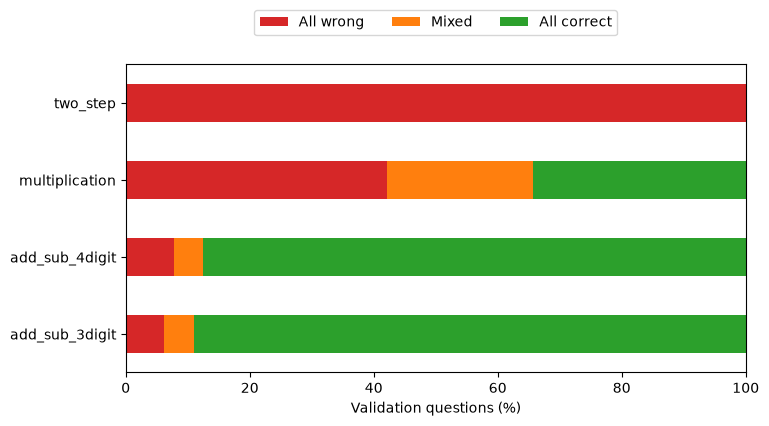

In [6]:
ax = calibration[["all_wrong", "mixed_groups", "all_correct"]].mul(100).rename(
    columns={
        "all_wrong": "All wrong",
        "mixed_groups": "Mixed",
        "all_correct": "All correct",
    }
).plot.barh(
    stacked=True,
    color=["tab:red", "tab:orange", "tab:green"],
    xlabel="Validation questions (%)",
    ylabel="",
    xlim=(0, 100),
    figsize=(8, 4),
)

ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.2), ncol=3)
ax.figure.savefig(asset_dir / "calibration.png", dpi=160, bbox_inches="tight")

### Selecting the training task

Multiplication produced mixed rewards for **15 of 64 questions (23.4%)**,
compared with **3 of 64 (4.7%)** for each larger addition/subtraction task.
Two-step expressions produced no reward variation under our verifier.

The SFT checkpoint answered **115 of 256 sampled multiplication responses
correctly (44.9%)**, with **100% valid integer responses**. This provides
a useful starting point for improving correctness through rewards.

We therefore select two-digit multiplication. GRPO will train only on
this task. The selection uses validation results; test results have not
determined the choice.

In [7]:
from datasets import Dataset
from trl import GRPOConfig, GRPOTrainer

from arithmetic_post_training.rewards import correctness_reward

task_name = "multiplication"
selected = tasks[task_name]
(run_dir / "selected-task.txt").write_text(task_name)

rl_data = {
    split: Dataset.from_list([
        {"prompt": row["prompt"], "answer": int(row["completion"])}
        for row in selected[split]
    ])
    for split in ("train", "validation")
}

### Learning from correctness rewards

The model receives the question and generates four responses.
The correct answer is used by the verifier, not supplied during generation.

One observed calibration group for `14 * 46` was:

| Response | Reward |
|----------|--------|
| 644      | 1      |
| 664      | 0      |
| 644      | 1      |
| 644      | 1      |

GRPO computes an advantage relative to the other responses:

$$
A_i = \frac{r_i - \bar{r}}{s_r + 10^{-4}}.
$$

Positive advantages encourage the sampled response; negative advantages
discourage it.

We use the original GRPO loss normalization, averaging generated-token
contributions within each response. This run uses one optimizer update
per sampled batch and no KL penalty.

In [8]:
use_bf16 = device == "cuda" and torch.cuda.is_bf16_supported()

args = GRPOConfig(
    output_dir=str(run_dir / "training"),
    max_steps=100,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,
    per_device_eval_batch_size=16,
    learning_rate=5e-6,
    warmup_steps=10,
    optim="adamw_torch",
    num_generations=4,
    max_completion_length=16,
    temperature=1.0,
    top_p=1.0,
    top_k=0,
    num_iterations=1,
    beta=0.0,
    loss_type="grpo",
    scale_rewards="group",
    disable_dropout=True,
    gradient_checkpointing=False,
    bf16=use_bf16,
    fp16=device == "cuda" and not use_bf16,
    dataloader_pin_memory=device == "cuda",
    logging_steps=10,
    eval_strategy="steps",
    eval_steps=25,
    save_strategy="no",
    report_to="none",
    seed=42,
)

trainer = GRPOTrainer(
    model=model,
    args=args,
    train_dataset=rl_data["train"],
    eval_dataset=rl_data["validation"],
    reward_funcs=correctness_reward,
    processing_class=tokenizer,
)

(run_dir / "training-args.json").write_text(args.to_json_string())

5848

### Record the starting checkpoint and train

Before updating the adapter, we save the SFT model's predictions on
200 multiplication test questions using both greedy decoding and four
sampled responses per question.

We also record greedy predictions on 200 original addition/subtraction
test questions to check retention later. These predictions are reserved
for the final comparison; the training settings are now fixed.

Training runs for 100 optimizer updates. On one device, each update
uses four questions with four responses each.

We measure sampled validation reward before training and every 25 updates.
The GRPO adapter is saved separately from the original SFT adapter.

In [9]:
retention = pd.read_csv(
    project_root / "runs" / "sft" / "test.csv"
).head(200).to_dict("records")

pd.DataFrame(retention).to_csv(run_dir / "retention.csv", index=False)

sft_test = evaluate_arithmetic(
    trainer.model, tokenizer, selected["test"], max_new_tokens=16
)

set_seed(123)
sft_sampled = evaluate_arithmetic(
    trainer.model,
    tokenizer,
    selected["test"],
    batch_size=4,
    max_new_tokens=16,
    num_generations=4,
    temperature=1.0,
)

sft_retention = evaluate_arithmetic(
    trainer.model, tokenizer, retention, max_new_tokens=8
)

sft_test.to_csv(run_dir / "sft-test.csv", index=False)
sft_sampled.to_csv(run_dir / "sft-sampled.csv", index=False)
sft_retention.to_csv(run_dir / "sft-retention.csv", index=False)

print("Saved SFT predictions for the final comparison.")

Saved SFT predictions for the final comparison.


In [10]:
set_seed(42)
initial_validation = trainer.evaluate()
trainer.train()

grpo_adapter_dir = run_dir / "adapter"
trainer.save_model(str(grpo_adapter_dir))
tokenizer.save_pretrained(str(grpo_adapter_dir))

history = pd.DataFrame([
    {"step": 0, **initial_validation},
    *trainer.state.log_history,
])
history.to_csv(run_dir / "training.csv", index=False)

print("Saved GRPO adapter:", grpo_adapter_dir)

Training Loss,Validation Loss,Step,Num Tokens,Completions/mean Length,Completions/min Length,Completions/max Length,Completions/clipped Ratio,Completions/mean Terminated Length,Completions/min Terminated Length,Completions/max Terminated Length,Rewards/correctness Reward/mean,Rewards/correctness Reward/std,Reward,Reward Std,Frac Reward Zero Std,Entropy,Clip Ratio/low Mean,Clip Ratio/high Mean,Clip Ratio/region Mean,Clip Ratio/low Min,Clip Ratio/high Max
No log,0.000000,0,0.000000,5.777344,5.375000,5.937500,0.000000,5.777344,5.375000,5.937500,0.437500,0.461903,0.437500,0.461903,0.765625,0.176581,0.000000,0.000000,0.000000,0.000000,0.000000


Step,Training Loss,Validation Loss,Num Tokens,Completions/mean Length,Completions/min Length,Completions/max Length,Completions/clipped Ratio,Completions/mean Terminated Length,Completions/min Terminated Length,Completions/max Terminated Length,Rewards/correctness Reward/mean,Rewards/correctness Reward/std,Reward,Reward Std,Frac Reward Zero Std,Entropy,Clip Ratio/low Mean,Clip Ratio/high Mean,Clip Ratio/region Mean,Clip Ratio/low Min,Clip Ratio/high Max
25,-0.000000,-0.000000,7923.000000,5.777344,5.375000,5.937500,0.000000,5.777344,5.375000,5.937500,0.468750,0.448596,0.468750,0.448596,0.734375,0.175551,0.000000,0.000000,0.000000,0.000000,0.000000
50,0.000000,0.000000,15860.000000,5.781250,5.375000,5.937500,0.000000,5.781250,5.375000,5.937500,0.472656,0.463643,0.472656,0.463643,0.656250,0.180275,0.000000,0.000000,0.000000,0.000000,0.000000
75,-0.000000,0.000000,23802.000000,5.785156,5.375000,6.000000,0.000000,5.785156,5.375000,6.000000,0.519531,0.439326,0.519531,0.439326,0.718750,0.181707,0.000000,0.000000,0.000000,0.000000,0.000000
100,-0.000000,0.000000,31752.000000,5.828125,5.375000,6.625000,0.000000,5.828125,5.375000,6.625000,0.496094,0.412523,0.496094,0.412523,0.656250,0.184445,0.000000,0.000000,0.000000,0.000000,0.000000


Saved GRPO adapter: /Users/shoaibakhtar/Developer/reasoning-models/arithmetic-post-training/runs/grpo/adapter


### Training diagnostics

With one update per sampled batch and no KL penalty, the averaged GRPO
loss can be near zero: advantages are centered, and policy ratios are
numerically one before the update. Gradients can still be nonzero because
the denominator is detached.

We therefore inspect sampled correctness, mixed-group fraction, and
gradient norm. Nonzero gradients indicate an optimization signal;
held-out evaluation is still needed to establish improvement.

Training rewards are averages over logging intervals. Validation rewards
use fresh samples on the same validation questions, so the curve can fluctuate.

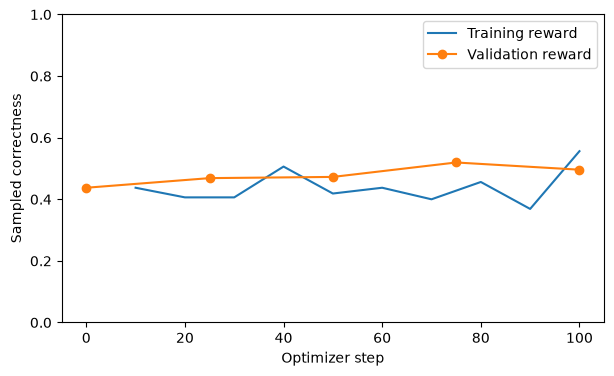

In [11]:
training = history.dropna(subset=["reward"])
validation = history.dropna(subset=["eval_reward"])

ax = training.plot(
    x="step",
    y="reward",
    label="Training reward",
    xlabel="Optimizer step",
    ylabel="Sampled correctness",
    ylim=(0, 1),
    figsize=(7, 4),
)

ax.plot(
    validation["step"],
    validation["eval_reward"],
    "o-",
    label="Validation reward",
)
ax.legend()

ax.figure.savefig(asset_dir / "reward.png", dpi=160, bbox_inches="tight")

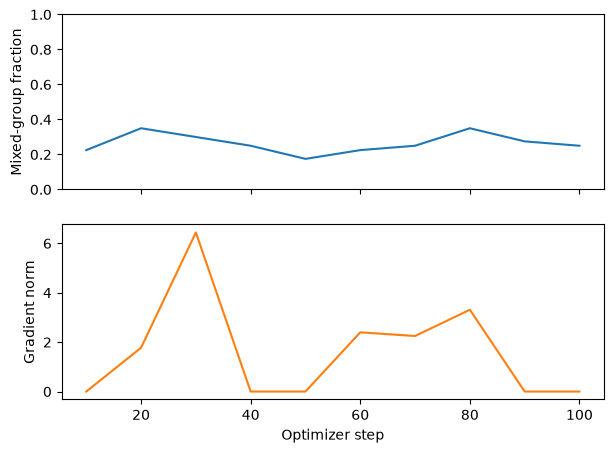

In [12]:
diagnostics = history.dropna(subset=["grad_norm"]).copy()
diagnostics["mixed_groups"] = 1 - diagnostics["frac_reward_zero_std"]

axes = diagnostics.plot(
    x="step",
    y=["mixed_groups", "grad_norm"],
    subplots=True,
    legend=False,
    figsize=(7, 5),
)

axes[0].set_ylabel("Mixed-group fraction")
axes[0].set_ylim(0, 1)
axes[1].set_ylabel("Gradient norm")
axes[1].set_xlabel("Optimizer step")

axes[0].figure.savefig(
    asset_dir / "diagnostics.png", dpi=160, bbox_inches="tight"
)

### Held-out evaluation

We compare SFT and GRPO on the same 200 multiplication test questions,
using greedy decoding and four sampled responses per question.
Sampled accuracy counts individual responses.

We also evaluate 200 original addition/subtraction questions to check
whether the model retains its earlier performance.

In [13]:
grpo_test = evaluate_arithmetic(
    trainer.model, tokenizer, selected["test"], max_new_tokens=16
)

set_seed(123)
grpo_sampled = evaluate_arithmetic(
    trainer.model,
    tokenizer,
    selected["test"],
    batch_size=4,
    max_new_tokens=16,
    num_generations=4,
    temperature=1.0,
)

grpo_retention = evaluate_arithmetic(
    trainer.model, tokenizer, retention, max_new_tokens=8
)

grpo_test.to_csv(run_dir / "grpo-test.csv", index=False)
grpo_sampled.to_csv(run_dir / "grpo-sampled.csv", index=False)
grpo_retention.to_csv(run_dir / "grpo-retention.csv", index=False)

In [14]:
results = pd.DataFrame([
    {
        "evaluation":label,
        "model":checkpoint,
        "responses":len(predictions),
        "accuracy":predictions["correct"].mean(),
        "valid_format":predictions["valid"].mean(),
    }
    for label, before, after in [
        ("Multiplication: greedy", sft_test, grpo_test),
        ("Multiplication: sampled", sft_sampled, grpo_sampled),
        ("Addition/subtraction: greedy", sft_retention, grpo_retention),
    ]
    for checkpoint, predictions in [("SFT", before), ("GRPO", after)]
])

results.to_csv(asset_dir / "results.csv", index=False)
results.round(4)

,evaluation,model,responses,accuracy,valid_format
0,Multiplication: greedy,SFT,200,0.5450,1.0000
1,Multiplication: greedy,GRPO,200,0.6050,1.0000
2,Multiplication: sampled,SFT,800,0.5062,0.9988
3,Multiplication: sampled,GRPO,800,0.5462,0.9962
4,Addition/subtraction: greedy,SFT,200,1.0000,1.0000
5,Addition/subtraction: greedy,GRPO,200,1.0000,1.0000


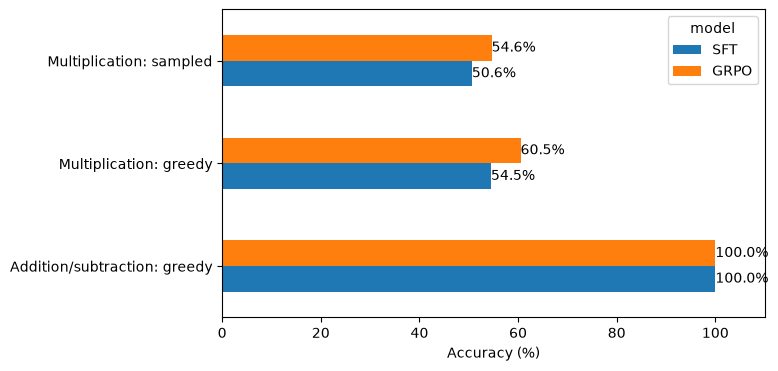

In [15]:
scores = results.pivot(
    index="evaluation", columns="model", values="accuracy"
)

ax = scores[["SFT", "GRPO"]].mul(100).plot.barh(
    xlim=(0, 110),
    xlabel="Accuracy (%)",
    ylabel="",
    figsize=(7, 4),
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

ax.figure.savefig(
    asset_dir / "accuracy.png", dpi=160, bbox_inches="tight"
)

In [16]:
examples = sft_test.merge(
    grpo_test,
    on=["prompt", "expected"],
    suffixes=("_sft", "_grpo"),
)[[
    "prompt",
    "expected",
    "response_sft",
    "response_grpo",
    "correct_sft",
    "correct_grpo",
]].head(10)

examples.to_csv(asset_dir / "examples.csv", index=False)
examples

,prompt,expected,response_sft,response_grpo,correct_sft,correct_grpo
0,Question: What is 62 * 64?\nAnswer:,3968,3888,3888,False,False
1,Question: What is 56 * 54?\nAnswer:,3024,3024,3024,True,True
2,Question: What is 34 * 51?\nAnswer:,1734,1654,1694,False,False
3,Question: What is 54 * 86?\nAnswer:,4644,4584,4584,False,False
4,Question: What is 93 * 13?\nAnswer:,1209,1209,1209,True,True
5,Question: What is 49 * 31?\nAnswer:,1519,1519,1519,True,True
6,Question: What is 54 * 88?\nAnswer:,4752,4672,4672,False,False
7,Question: What is 66 * 89?\nAnswer:,5874,5914,5974,False,False
8,Question: What is 28 * 66?\nAnswer:,1848,1848,1848,True,True
9,Question: What is 15 * 39?\nAnswer:,585,635,615,False,False


### Interpretation

We selected multiplication using development-set mixed-reward groups,
then trained the SFT adapter for 100 GRPO updates using binary
correctness rewards.

| Evaluation | SFT | GRPO |
|------------|-----|------|
| Multiplication: greedy | 109/200 (54.5%) | 121/200 (60.5%) |
| Multiplication: sampled | 405/800 (50.625%) | 437/800 (54.625%) |
| Addition/subtraction: greedy | 200/200 (100%) | 200/200 (100%) |

Greedy multiplication accuracy increased by **6 percentage points**:
13 previously incorrect answers became correct, while one correct answer
became incorrect. Sampled accuracy increased by **4 percentage points**,
measured over four responses per test question.

Both checkpoints produced valid integers for every greedy response.
Sampled format validity decreased slightly, from 799/800 to 797/800.
The retention check found no accuracy decrease on the 200 original
addition/subtraction questions.

The near-zero policy loss is expected with centered advantages, one
update per sampled batch, and no KL penalty. Nonzero gradients and
changed adapter weights confirm that optimization occurred; the
held-out comparison measures its effect on accuracy.

This single run demonstrates a working SFT-to-GRPO pipeline and an
observed improvement on multiplication. It does not establish
repeatability across seeds or superiority over additional SFT.
Exact questions are held out, but reversed operand orders may appear
across splits.

Notebook 03 introduces a target-number environment. The model chooses
arithmetic moves, receives state updates, and is trained with GRPO
over complete interactions.